# Check ΔF/F for any session and run
Set SESSION_NUMBER and RUN_NUMBER below, then restart the kernel and run all cells. The subject defaults to MY_71_R.
Run cells in order using the `mini2p-preprocessing` environment. This notebook reads existing Suite2p outputs; it does not perform extraction or overwrite them. Ensure conversion has completed for this run: files left from an older extraction may also exist.

We calculate `F_corrected = F − neucoeff × Fneu`, then `(F_corrected − F0) / F0`, with each ROI's 20th percentile over the entire run as a fixed baseline. This is a baseline choice, not the Suite2p spike-preprocessing output. ΔF/F is fractional (0.1 = 10%). Small positive baselines can inflate values; nonpositive baselines are flagged and excluded. Channel 2 uses the same ROIs; verify acquisition settings before calling it red.


In [7]:
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SUBJECT_DIR = Path('/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R')
SESSION_NUMBER = 216
RUN_NUMBER = 4  # Preserves the run currently selected in this notebook.

matches = sorted(SUBJECT_DIR.glob(
    f'ses-{SESSION_NUMBER}_*/funcimg/run-{RUN_NUMBER:02d}/suite2p/plane0'))
if len(matches) != 1:
    raise FileNotFoundError(
        f'Expected one plane0 folder for session {SESSION_NUMBER}, run {RUN_NUMBER}; '
        f'found {len(matches)}: {matches}')
PLANE = matches[0]
RUN_LABEL = f'Session {SESSION_NUMBER}, run {RUN_NUMBER:02d}'
print(RUN_LABEL, PLANE, sep=': ')
BASELINE_PERCENTILE = 20
MIN_F0 = 0.0  # Baselines must exceed this value; units are fluorescence units.
FS_OVERRIDE = None  # Set only if ops['fs'] is absent/incorrect.
CHECK_CHANNEL_2 = True


Session 216, run 04: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-216_date-20260730/funcimg/run-04/suite2p/plane0


In [8]:
required = ['F.npy', 'Fneu.npy', 'ops.npy', 'stat.npy', 'iscell.npy']
missing = [name for name in required if not (PLANE / name).is_file()]
if missing:
    raise FileNotFoundError(f'Complete conversion for this run first. Missing: {missing}')
display(pd.DataFrame([{'file': name,
    'modified': datetime.fromtimestamp((PLANE / name).stat().st_mtime).isoformat(timespec='seconds'),
    'size_MB': (PLANE / name).stat().st_size / 1e6} for name in required]))
ops = np.load(PLANE / 'ops.npy', allow_pickle=True).item()
stat = np.load(PLANE / 'stat.npy', allow_pickle=True)
iscell = np.load(PLANE / 'iscell.npy', allow_pickle=True)
neucoeff = float(ops.get('neucoeff', 0.7))
fs = float(FS_OVERRIDE if FS_OVERRIDE is not None else ops.get('fs', np.nan))
if not np.isfinite(fs) or fs <= 0:
    raise ValueError('Set FS_OVERRIDE to the verified sampling rate in Hz.')
print(f'Neuropil coefficient: {neucoeff}; sampling rate: {fs} Hz')
print({key: ops.get(key, 'not recorded') for key in ['nchannels', 'functional_chan', 'align_by_chan']})
print('File presence and timestamps do not prove these came from the latest Cellpose conversion.')


,file,modified,size_MB
0,F.npy,2026-10-11T17:48:17,13.604928
1,Fneu.npy,2026-10-11T17:48:20,13.604928
2,ops.npy,2026-10-11T17:48:35,45.719145
3,stat.npy,2026-10-11T17:48:39,1.369660
4,iscell.npy,2026-10-11T17:48:26,0.006528


Neuropil coefficient: 0.7; sampling rate: 7.52 Hz
{'nchannels': 2, 'functional_chan': 2, 'align_by_chan': 'not recorded'}
File presence and timestamps do not prove these came from the latest Cellpose conversion.


In [9]:
def calculate_dff(F, Fneu, coefficient, percentile=20, min_f0=0):
    F = np.asarray(F, dtype=np.float64)
    Fneu = np.asarray(Fneu, dtype=np.float64)
    if F.ndim != 2 or F.shape != Fneu.shape or 0 in F.shape:
        raise ValueError(f'Expected matching nonempty ROI × frame arrays: {F.shape}, {Fneu.shape}')
    if not 0 <= percentile <= 100 or min_f0 < 0 or not np.isfinite(coefficient):
        raise ValueError('Check percentile, minimum baseline, and neuropil coefficient.')
    corrected = F - coefficient * Fneu
    finite = np.isfinite(corrected).all(axis=1)
    F0 = np.full((len(F), 1), np.nan)
    F0[finite] = np.percentile(corrected[finite], percentile, axis=1, keepdims=True)
    valid = finite & (F0[:, 0] > min_f0)
    dff = np.full_like(corrected, np.nan)
    np.divide(corrected - F0, F0, out=dff, where=valid[:, None])
    return dict(F=F, Fneu=Fneu, corrected=corrected, F0=F0, dff=dff, valid=valid)

channels = {}
for label, names in [('functional', ('F.npy', 'Fneu.npy')),
                      ('channel2', ('F_chan2.npy', 'Fneu_chan2.npy'))]:
    if label == 'channel2' and not CHECK_CHANNEL_2:
        continue
    present = [(PLANE / name).is_file() for name in names]
    if label == 'channel2' and not any(present):
        print('Channel 2 files absent; checking functional channel only.')
        continue
    if not all(present):
        raise FileNotFoundError(f'Incomplete fluorescence pair: {names}')
    result = calculate_dff(*(np.load(PLANE / name) for name in names),
                           neucoeff, BASELINE_PERCENTILE, MIN_F0)
    if len(result['F']) != len(stat) or iscell.shape != (len(stat), 2):
        raise ValueError('ROI counts disagree between fluorescence, stat, and iscell.')
    if channels and result['F'].shape != channels['functional']['F'].shape:
        raise ValueError('Channel shapes disagree.')
    channels[label] = result
    print(f"{label}: {result['F'].shape[0]} ROIs × {result['F'].shape[1]} frames; "
          f"{result['F'].shape[1] / fs / 60:.2f} minutes; "
          f"{result['valid'].sum()} valid baselines")


functional: 400 ROIs × 8503 frames; 18.85 minutes; 400 valid baselines
channel2: 400 ROIs × 8503 frames; 18.85 minutes; 400 valid baselines


## Select an ROI on the mean image
The dropdown includes every ROI in `stat.npy`; select any ROI independently of the stacked plots. The highlighted pixels are that ROI's exact extraction mask. The trace below shows its first 2,000 frames. This uses `ops['meanImg']`, with `meanImgE` as a fallback. Image contrast is adjusted for display only.


In [10]:
import ipywidgets as widgets
from IPython.display import display, clear_output

image_key = next((key for key in ('meanImg', 'meanImgE') if key in ops), None)
if image_key is None:
    raise KeyError("No meanImg or meanImgE found in ops.npy.")
mean_image = np.asarray(ops[image_key])
if mean_image.ndim != 2 or not np.isfinite(mean_image).any():
    raise ValueError('Expected a 2D mean image with finite values.')
vmin, vmax = np.percentile(mean_image[np.isfinite(mean_image)], [1, 99])
if vmax <= vmin:
    vmax = vmin + 1
rank_lookup = {}
options = []
for roi in range(len(stat)):
    label = f'ROI {roi}'
    if roi in rank_lookup:
        label += f' — top 30, rank {rank_lookup[roi]}'
    label += ' — cell' if iscell[roi, 0] == 1 else ' — not classified as cell'
    options.append((label, roi))
roi_dropdown = widgets.Dropdown(options=options, value=0,
                               description='ROI:', layout=widgets.Layout(width='550px'))
roi_output = widgets.Output()

def show_selected_roi(change=None):
    roi = roi_dropdown.value
    ypix = np.asarray(stat[roi]['ypix'], dtype=int)
    xpix = np.asarray(stat[roi]['xpix'], dtype=int)
    if (np.any(ypix < 0) or np.any(ypix >= mean_image.shape[0])
            or np.any(xpix < 0) or np.any(xpix >= mean_image.shape[1])):
        raise ValueError('ROI coordinates do not match the mean-image dimensions.')
    overlay = np.zeros((*mean_image.shape, 4), dtype=float)
    overlay[ypix, xpix] = [1, 0.15, 0, 0.7]
    with roi_output:
        clear_output(wait=True)
        fig, axes = plt.subplots(1, 2, figsize=(15, 5),
                                 gridspec_kw={'width_ratios': [1, 2]},
                                 constrained_layout=True)
        axes[0].imshow(mean_image, cmap='gray', vmin=vmin, vmax=vmax,
                       origin='upper', interpolation='nearest')
        axes[0].imshow(overlay, origin='upper', interpolation='nearest')
        axes[0].set(title=f'{image_key}: ROI {roi} highlighted', xlabel='x pixel', ylabel='y pixel')
        trace = channels['functional']['dff'][roi]
        axes[1].plot(trace, lw=0.7)
        axes[1].set(title=f'ROI {roi} — first {len(trace)} frames', xlabel='Frame', ylabel='ΔF/F')
        axes[1].spines['top'].set_visible(False)
        axes[1].spines['right'].set_visible(False)
        if not channels['functional']['valid'][roi]:
            axes[1].text(0.5, 0.5, 'Invalid baseline: ΔF/F unavailable',
                         transform=axes[1].transAxes, ha='center')
        plt.show()

roi_dropdown.observe(show_selected_roi, names='value')
display(roi_dropdown, roi_output)
show_selected_roi()


Dropdown(description='ROI:', layout=Layout(width='550px'), options=(('ROI 0 — cell', 0), ('ROI 1 — cell', 1), …

Output()

## Whole-recording ΔF/F and z-scored ΔF/F
The same selected cells appear in two stacked plots: original fractional ΔF/F (0.1 = 10%) and per-cell z-scored ΔF/F. Ranking uses the 99th percentile of ΔF/F over the whole recording. Vertical offsets separate traces without changing their amplitudes. Original-unit spacing is adjustable; z-scoring changes display only. ROI order and colors match the raw F plots below.


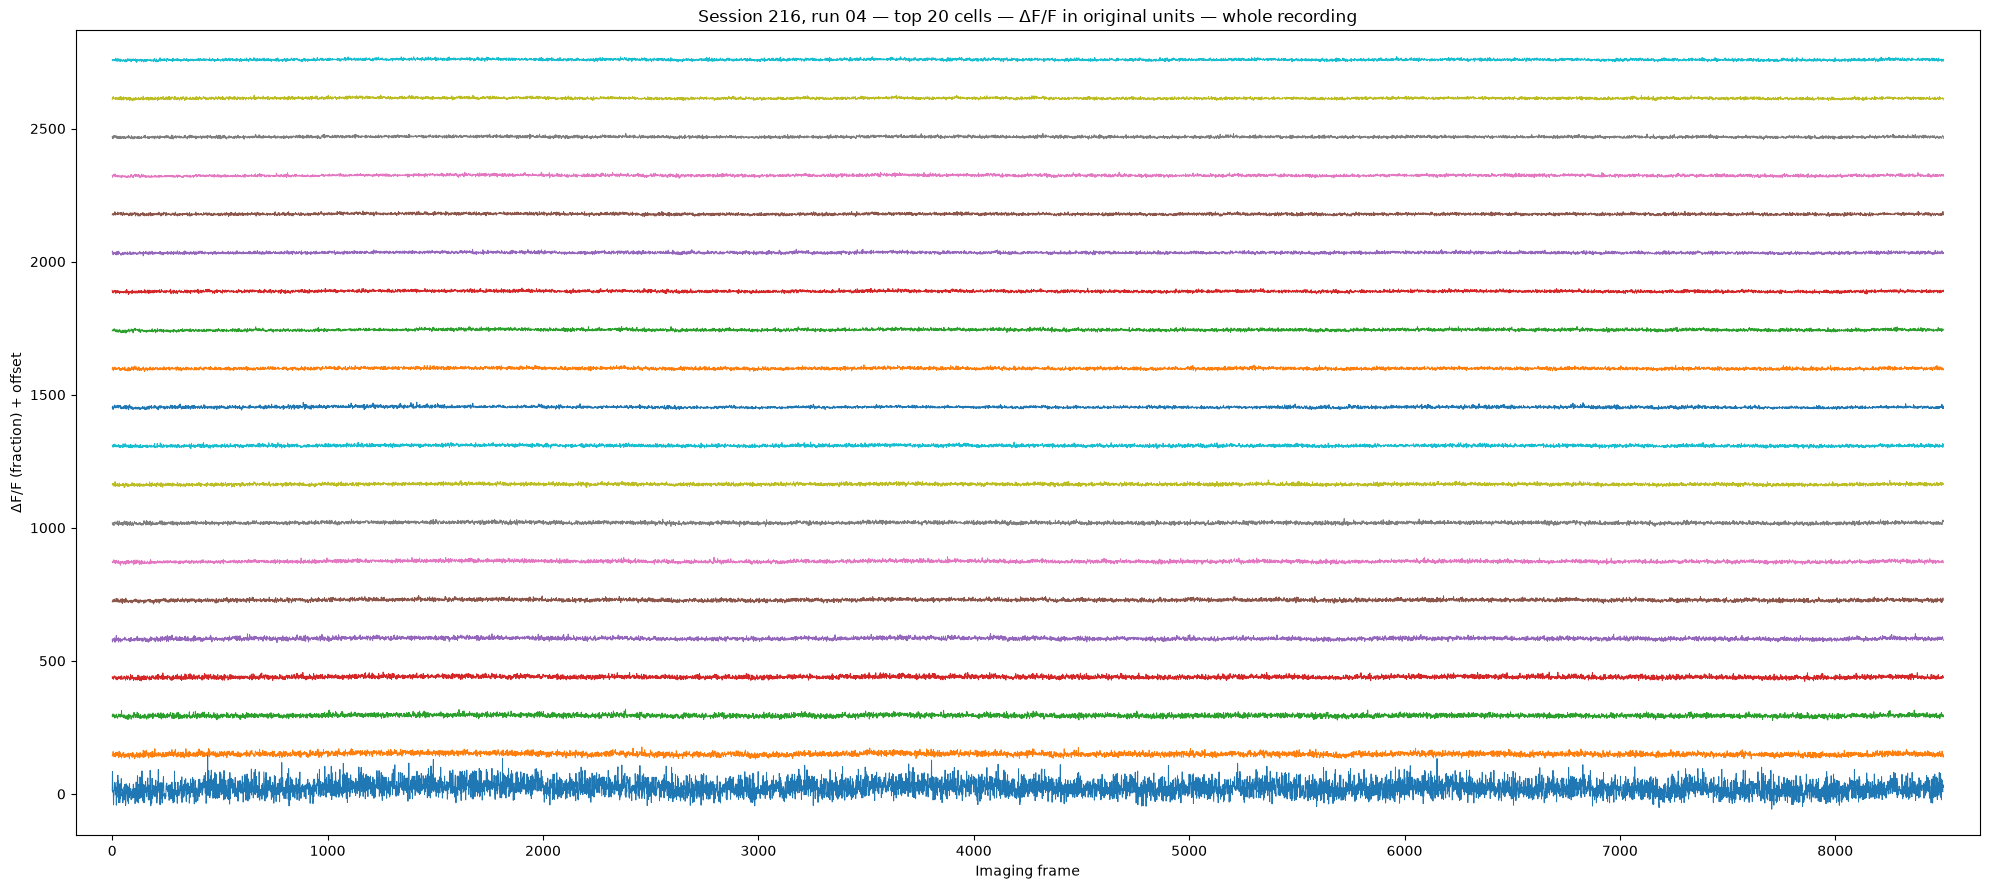

ΔF/F in original units: vertical offset per row = 145.068


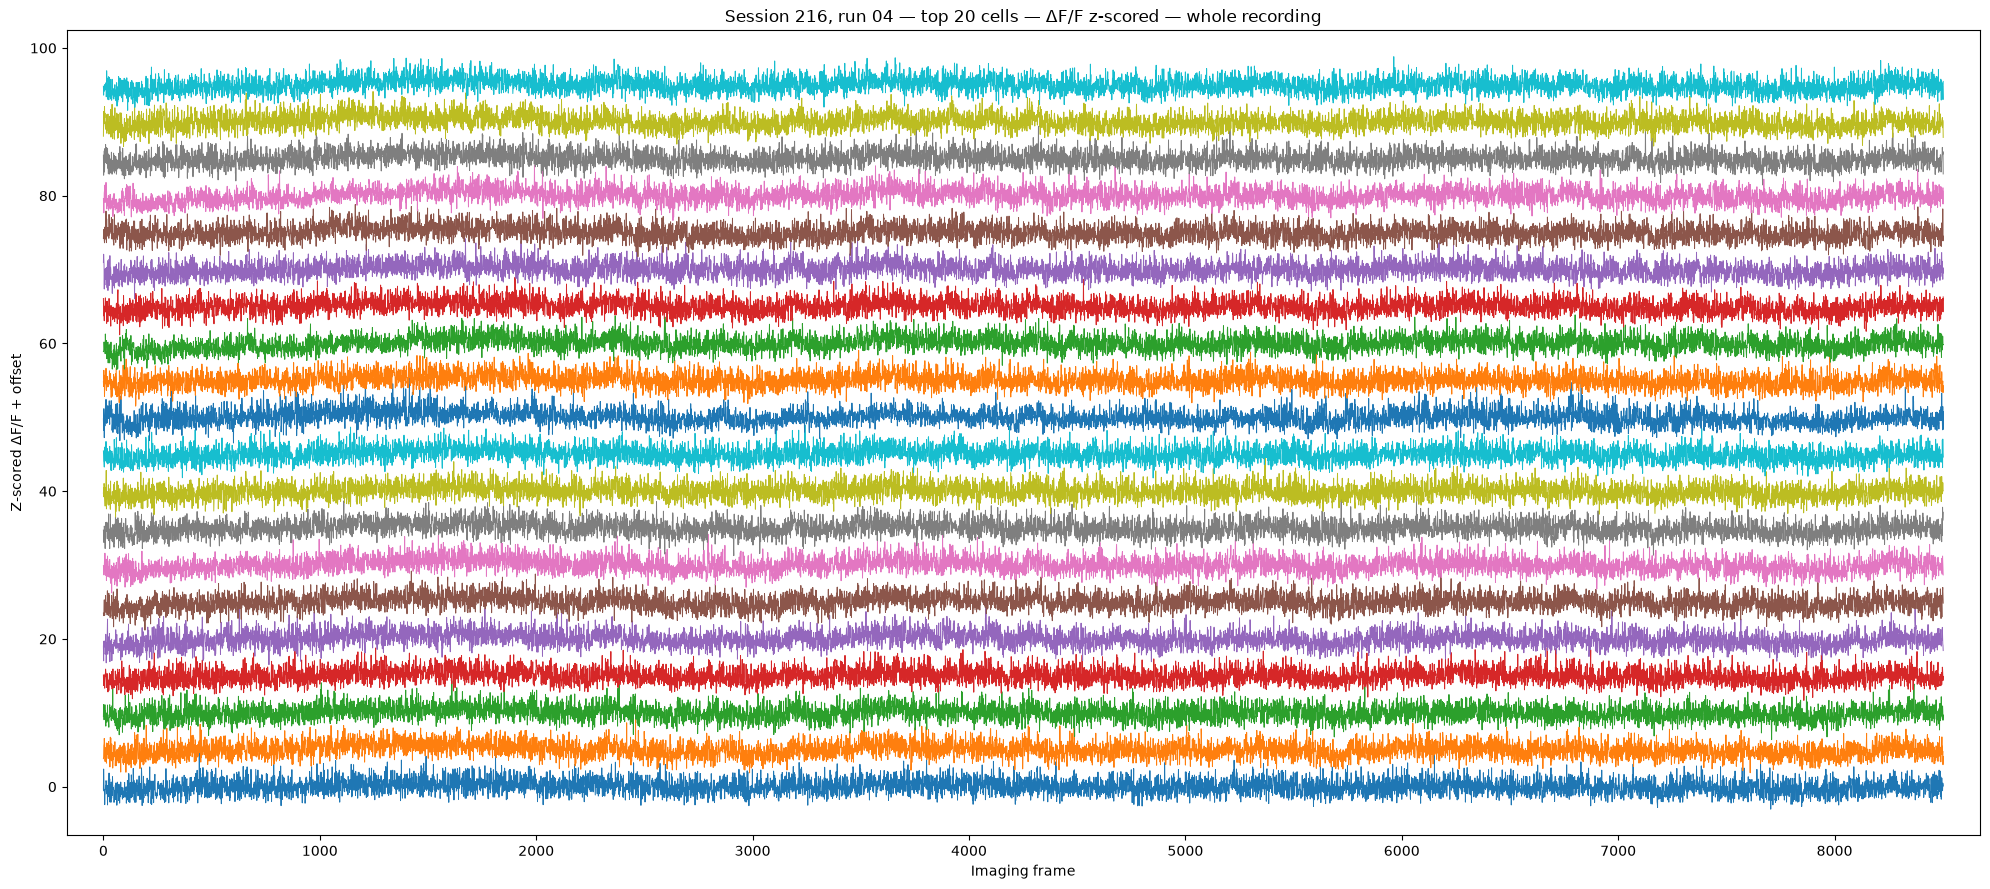

ΔF/F z-scored: vertical offset per row = 5
ROI IDs, bottom to top: [338, 358, 394, 383, 382, 396, 305, 370, 355, 303, 250, 340, 2, 388, 393, 263, 257, 152, 300, 304]
Display scaling does not modify the original ΔF/F arrays.


In [11]:
N_STACKED_CELLS = 20
TRACE_SPACING = 5.0
DFF_SPACING = None  # None uses the largest per-cell 1st–99th percentile range.

r = channels['functional']
candidates = np.flatnonzero((iscell[:, 0] == 1) & r['valid'])
if candidates.size == 0:
    raise ValueError('No classified cells with valid ΔF/F baselines.')
scores = np.percentile(r['dff'][candidates], 99, axis=1)
stacked_rois = candidates[np.argsort(-scores, kind='stable')[:N_STACKED_CELLS]]
traces = np.asarray(r['dff'][stacked_rois], dtype=float)
trace_mean = traces.mean(axis=1, keepdims=True)
trace_std = traces.std(axis=1, keepdims=True)
zscored = np.divide(traces - trace_mean, trace_std,
                    out=np.zeros_like(traces), where=trace_std > 0)
frames = np.arange(traces.shape[1])
offsets = np.arange(len(stacked_rois)) * TRACE_SPACING
colors = plt.get_cmap('tab10')

if DFF_SPACING is None:
    ranges = np.percentile(traces, 99, axis=1) - np.percentile(traces, 1, axis=1)
    dff_spacing = max(float(np.max(ranges)) * 1.2, 0.1)
else:
    dff_spacing = float(DFF_SPACING)
if not np.isfinite(dff_spacing) or dff_spacing <= 0:
    raise ValueError('DFF_SPACING must be positive and finite.')

for shown, spacing, units, title in [
    (traces, dff_spacing, 'ΔF/F (fraction) + offset', 'ΔF/F in original units'),
    (zscored, TRACE_SPACING, 'Z-scored ΔF/F + offset', 'ΔF/F z-scored'),
]:
    offsets = np.arange(len(stacked_rois)) * spacing
    fig, ax = plt.subplots(figsize=(20, max(8, 0.45 * len(stacked_rois))))
    for row, roi in enumerate(stacked_rois):
        ax.plot(frames, shown[row] + offsets[row],
                color=colors(row % 10), lw=0.7)
    ax.set_xlabel('Imaging frame')
    ax.set_ylabel(units)
    ax.set_title(f'{RUN_LABEL} — top {len(stacked_rois)} cells — {title} — whole recording')
    ax.margins(x=0.02, y=0.035)
    fig.tight_layout()
    plt.show()
    print(f'{title}: vertical offset per row = {spacing:g}')
print('ROI IDs, bottom to top:', stacked_rois.tolist())
print('Display scaling does not modify the original ΔF/F arrays.')


## Raw F in both channels — whole recording
Use the same ROI IDs and bottom-to-top order as the final ΔF/F plot. Each channel's raw F is independently z-scored per ROI and vertically offset, matching the reference style. These are F.npy and F_chan2.npy before neuropil subtraction, not ΔF/F. Z-scoring hides absolute fluorescence levels; set ZSCORE_RAW_F = False to show original fluorescence units with automatic spacing. Channel names follow Suite2p output files; confirm acquisition settings for green/red identity.


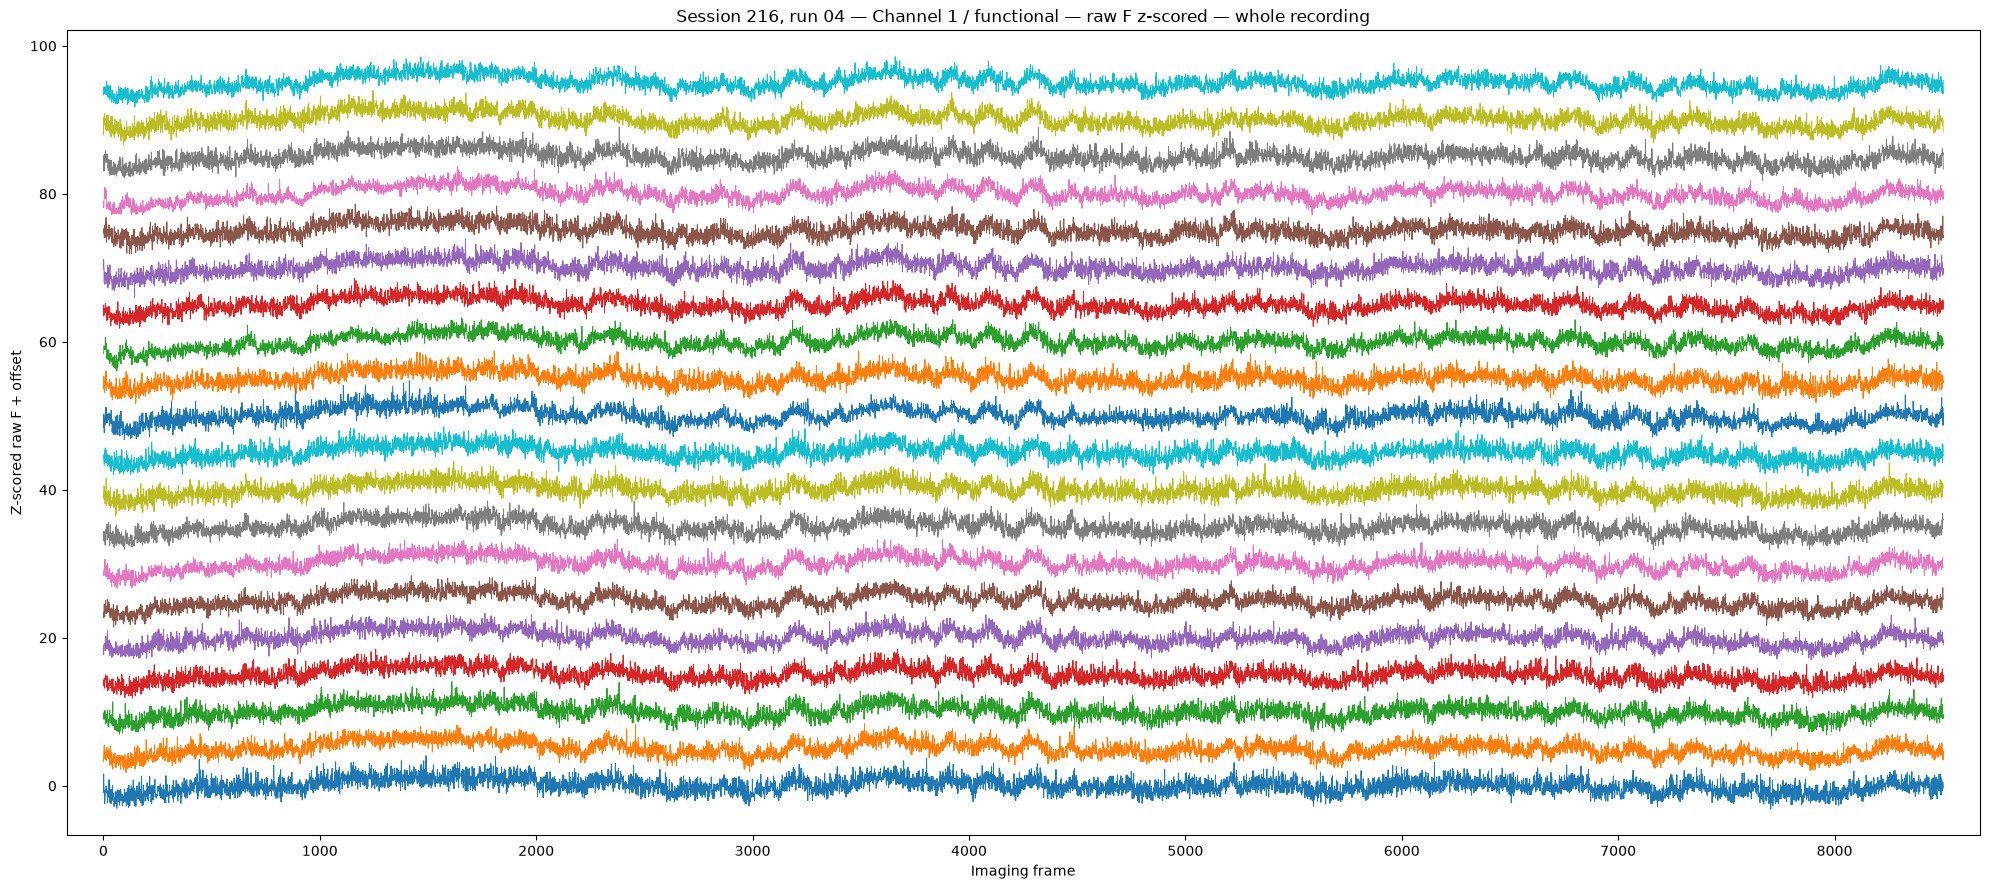

Channel 1 / functional: ROI IDs bottom to top: [338, 358, 394, 383, 382, 396, 305, 370, 355, 303, 250, 340, 2, 388, 393, 263, 257, 152, 300, 304]
Vertical offset per row: 5


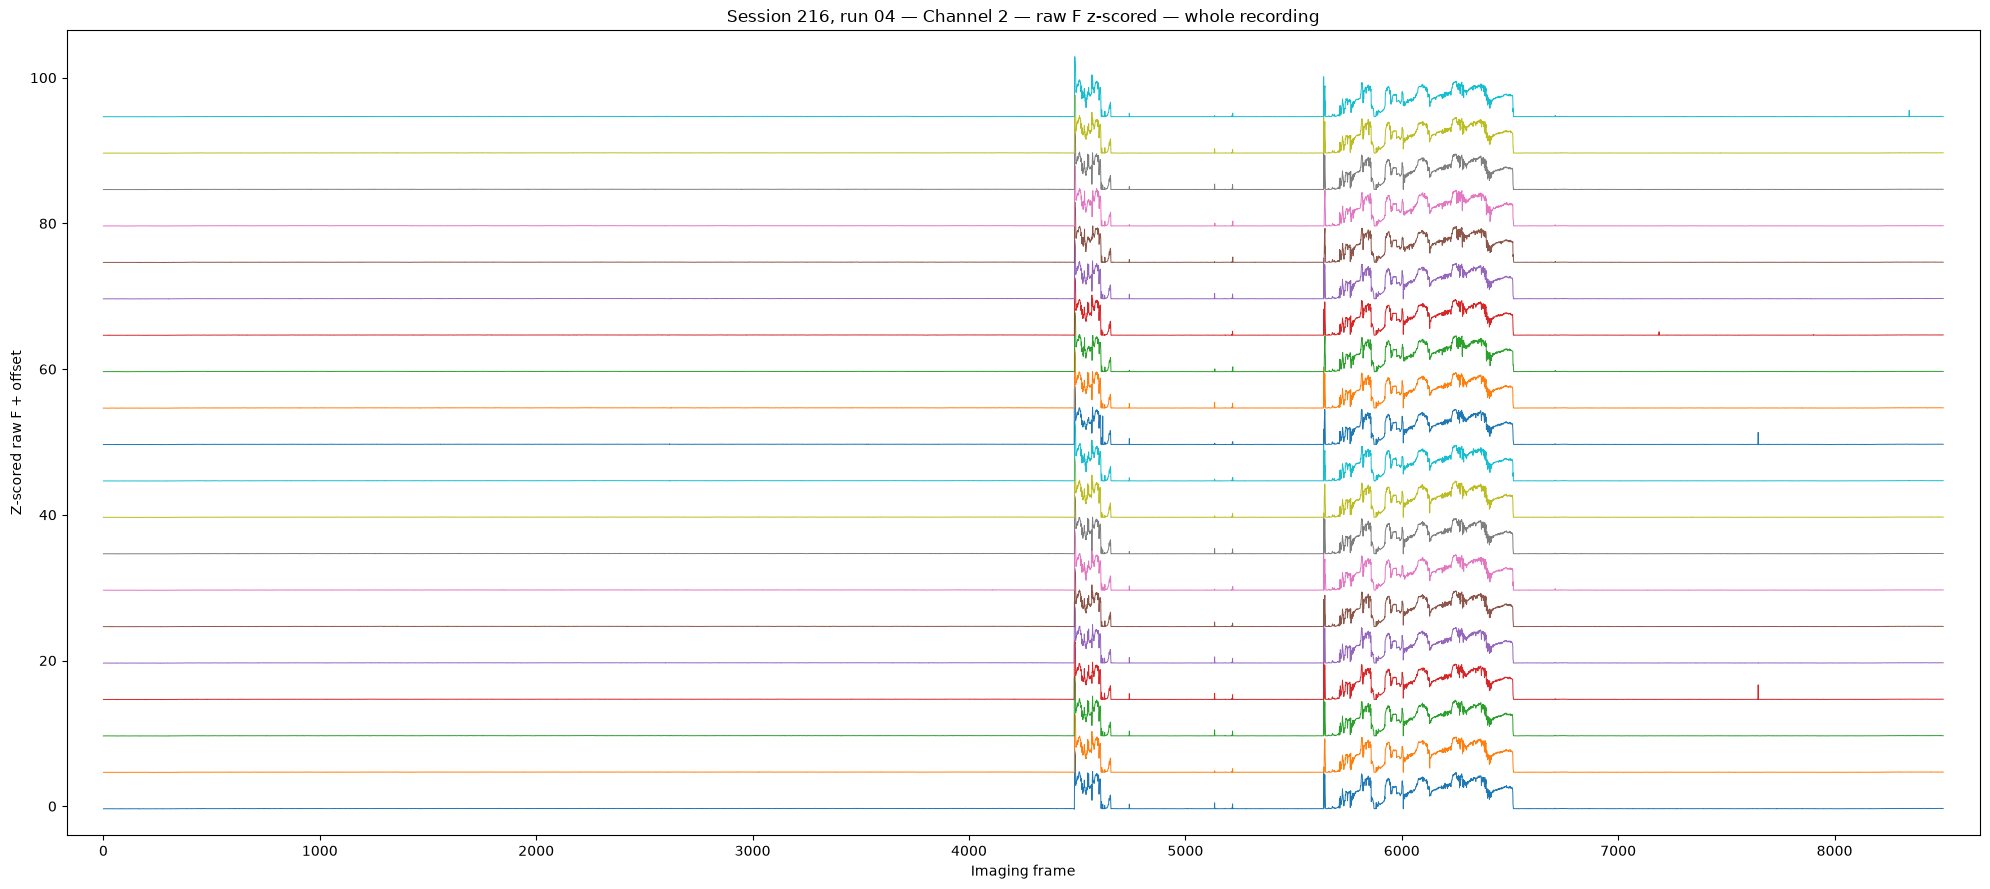

Channel 2: ROI IDs bottom to top: [338, 358, 394, 383, 382, 396, 305, 370, 355, 303, 250, 340, 2, 388, 393, 263, 257, 152, 300, 304]
Vertical offset per row: 5


In [12]:
ZSCORE_RAW_F = True
RAW_F_Z_SPACING = 5.0

# Run the whole-recording ΔF/F stacked cell first to select matching cells.
if 'stacked_rois' not in globals():
    raise RuntimeError('Run the preceding whole-recording stacked ΔF/F cell first.')

for channel_label, filename in [('Channel 1 / functional', 'F.npy'),
                                 ('Channel 2', 'F_chan2.npy')]:
    path = PLANE / filename
    if not path.is_file():
        print(f'Skipping {channel_label}: {filename} is missing.')
        continue
    raw = np.load(path, mmap_mode='r')
    if raw.ndim != 2 or raw.shape != channels['functional']['F'].shape:
        raise ValueError(f'{filename}: expected the same ROI × frame shape as functional F.')
    traces = np.asarray(raw[stacked_rois], dtype=float)
    finite_rows = np.isfinite(traces).all(axis=1)
    if not finite_rows.all():
        print(f'{channel_label}: nonfinite samples in ROIs {stacked_rois[~finite_rows].tolist()}')
    if ZSCORE_RAW_F:
        means = np.nanmean(traces, axis=1, keepdims=True)
        stds = np.nanstd(traces, axis=1, keepdims=True)
        shown = np.divide(traces - means, stds,
                          out=np.zeros_like(traces), where=stds > 0)
        shown[~np.isfinite(traces)] = np.nan
        spacing = RAW_F_Z_SPACING
        units = 'Z-scored raw F + offset'
        mode_label = 'raw F z-scored'
    else:
        # Preserve absolute F levels; offsets are display shifts only.
        shown = traces
        finite_values = traces[np.isfinite(traces)]
        if finite_values.size == 0:
            print(f'Skipping {channel_label}: no finite fluorescence samples.')
            continue
        spacing = max(float(np.ptp(finite_values)) * 1.1, 1.0)
        units = 'Raw F (fluorescence units) + offset'
        mode_label = 'raw F, original units'
    frames = np.arange(traces.shape[1])
    offsets = np.arange(len(stacked_rois)) * spacing
    fig, ax = plt.subplots(figsize=(20, max(8, 0.45 * len(stacked_rois))))
    for row, roi in enumerate(stacked_rois):
        ax.plot(frames, shown[row] + offsets[row],
                color=plt.get_cmap('tab10')(row % 10), lw=0.7)
    ax.set(xlabel='Imaging frame', ylabel=units,
           title=f'{RUN_LABEL} — {channel_label} — {mode_label} — whole recording')
    ax.margins(x=0.02, y=0.035)
    fig.tight_layout()
    plt.show()
    print(f'{channel_label}: ROI IDs bottom to top: {stacked_rois.tolist()}')
    print(f'Vertical offset per row: {spacing:g}')
